# 02. v1 모델링 — 특징 기반 ML

**순서:** Random Forest (베이스라인) → XGBoost (주력 + 튜닝) → SVM (비교)  
**평가:** Macro F1 with GroupKFold (group = 악기) — 악기 하나씩 테스트셋으로 빠지는 4-fold  
**해석:** Feature Importance → SHAP

In [34]:
import sys, warnings
warnings.filterwarnings('ignore')
sys.path.append('../src')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import shap

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.metrics import (
    f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
)
import xgboost as xgb
from sklearn.model_selection import GridSearchCV

from features import FEATURE_NAMES

plt.rcParams['figure.dpi'] = 100
CLASSES   = ['ordinario', 'pizzicato_secco', 'tremolo', 'sul_ponticello', 'col_legno_battuto']
LABEL2ID  = {c: i for i, c in enumerate(CLASSES)}
ID2LABEL  = {i: c for c, i in LABEL2ID.items()}

In [35]:
df = pd.read_csv('../data/features_full.csv')

X      = df[FEATURE_NAMES].values.astype(float)
y      = df['label_id'].values
groups = df['instrument'].values     # GroupKFold 그룹 키

gkf = GroupKFold(n_splits=4)        # 악기 4종 → 4-fold

RESULTS_DIR = Path('../results/v1')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f'X: {X.shape},  y: {y.shape}')
print('그룹(악기):', np.unique(groups))
print(f'결과 저장 위치: {RESULTS_DIR.resolve()}')

X: (3402, 245),  y: (3402,)
그룹(악기): ['Contrabass' 'Viola' 'Violin' 'Violoncello']
결과 저장 위치: /Users/juan/Desktop/실습/주법 분류모델/results/v1


## 1. Random Forest — 베이스라인

튜닝 없이 돌려서 기준 성능을 잡는다.  
RF는 스케일에 무관하므로 StandardScaler 불필요.

In [36]:
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)

cv_rf = cross_validate(
    rf, X, y, groups=groups, cv=gkf,
    scoring='f1_macro', return_train_score=True
)

print('=== Random Forest ===')
print(f'Train Macro F1: {cv_rf["train_score"].mean():.4f} ± {cv_rf["train_score"].std():.4f}')
print(f'Test  Macro F1: {cv_rf["test_score"].mean():.4f} ± {cv_rf["test_score"].std():.4f}')

=== Random Forest ===
Train Macro F1: 1.0000 ± 0.0000
Test  Macro F1: 0.8862 ± 0.0601


## 2. XGBoost — 주력 모델

### 2-1. 기본 설정으로 우선 평가

In [37]:
xgb_base = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1,
)

cv_xgb = cross_validate(
    xgb_base, X, y, groups=groups, cv=gkf,
    scoring='f1_macro', return_train_score=True
)

print('=== XGBoost (기본값) ===')
print(f'Train Macro F1: {cv_xgb["train_score"].mean():.4f} ± {cv_xgb["train_score"].std():.4f}')
print(f'Test  Macro F1: {cv_xgb["test_score"].mean():.4f} ± {cv_xgb["test_score"].std():.4f}')

=== XGBoost (기본값) ===
Train Macro F1: 1.0000 ± 0.0000
Test  Macro F1: 0.8912 ± 0.0256


### 2-2. GridSearchCV 하이퍼파라미터 튜닝

In [38]:
param_grid = {
    'n_estimators':  [100, 300],
    'max_depth':     [3, 5, 7],
    'learning_rate': [0.05, 0.1, 0.2],
    'subsample':     [0.8, 1.0],
}

gs = GridSearchCV(
    xgb.XGBClassifier(eval_metric='mlogloss', random_state=42, n_jobs=-1),
    param_grid,
    cv=gkf,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1,
)
gs.fit(X, y, groups=groups)

print('최적 파라미터:', gs.best_params_)
print(f'최적 Macro F1: {gs.best_score_:.4f}')

Fitting 4 folds for each of 36 candidates, totalling 144 fits
최적 파라미터: {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 300, 'subsample': 0.8}
최적 Macro F1: 0.8914


In [39]:
# 최적 모델로 전체 데이터 재학습 (Feature Importance / SHAP용)
best_xgb = gs.best_estimator_
best_xgb.fit(X, y)
print('재학습 완료')

재학습 완료


## 3. SVM — 비교 모델

SVM은 스케일에 민감하므로 Pipeline에 StandardScaler를 포함한다.

In [40]:
svm_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=10, gamma='scale', random_state=42)),
])

cv_svm = cross_validate(
    svm_pipe, X, y, groups=groups, cv=gkf,
    scoring='f1_macro', return_train_score=True
)

print('=== SVM (RBF kernel) ===')
print(f'Train Macro F1: {cv_svm["train_score"].mean():.4f} ± {cv_svm["train_score"].std():.4f}')
print(f'Test  Macro F1: {cv_svm["test_score"].mean():.4f} ± {cv_svm["test_score"].std():.4f}')

=== SVM (RBF kernel) ===
Train Macro F1: 1.0000 ± 0.0000
Test  Macro F1: 0.9159 ± 0.0113


## 4. 모델 성능 비교

,Model,Test F1,Std,Train F1
0,Random Forest,0.8862,0.0601,1.0
1,XGBoost (default),0.8912,0.0256,1.0
2,XGBoost (tuned),0.8914,0.0000,NaN
3,SVM,0.9159,0.0113,1.0


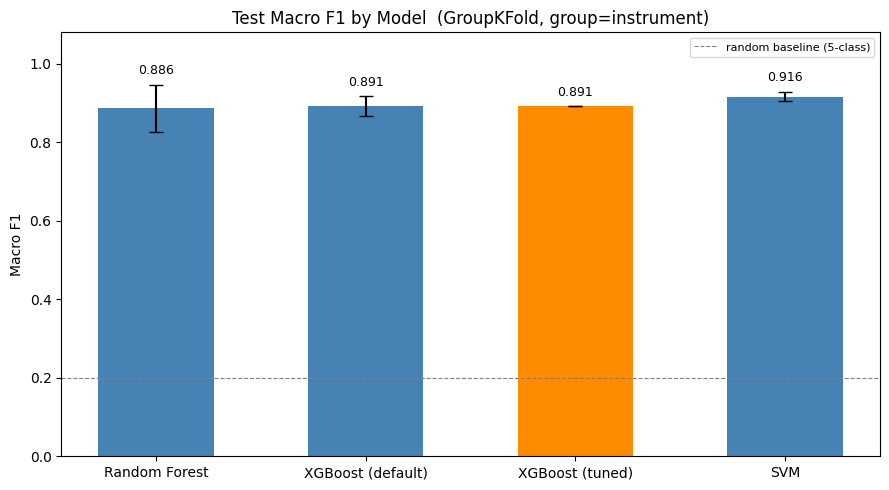

Saved: model_comparison.csv, model_comparison.png


In [41]:
results = pd.DataFrame({
    'Model':    ['Random Forest', 'XGBoost (default)', 'XGBoost (tuned)', 'SVM'],
    'Test F1':  [
        cv_rf['test_score'].mean(),
        cv_xgb['test_score'].mean(),
        gs.best_score_,
        cv_svm['test_score'].mean(),
    ],
    'Std': [
        cv_rf['test_score'].std(),
        cv_xgb['test_score'].std(),
        0.0,
        cv_svm['test_score'].std(),
    ],
    'Train F1': [
        cv_rf['train_score'].mean(),
        cv_xgb['train_score'].mean(),
        None,
        cv_svm['train_score'].mean(),
    ],
}).round(4)

display(results)
results.to_csv(RESULTS_DIR / 'model_comparison.csv', index=False)

fig, ax = plt.subplots(figsize=(9, 5))
colors = ['steelblue', 'steelblue', 'darkorange', 'steelblue']
bars = ax.bar(
    results['Model'], results['Test F1'],
    color=colors, yerr=results['Std'], capsize=5,
    error_kw={'elinewidth': 1.5, 'ecolor': 'black'},
    width=0.55,
)
ax.set_ylabel('Macro F1')
ax.set_ylim(0, 1.08)
ax.set_title('Test Macro F1 by Model  (GroupKFold, group=instrument)')
ax.axhline(0.2, color='gray', linestyle='--', lw=0.8, label='random baseline (5-class)')
ax.legend(fontsize=8)

for bar, std_val in zip(bars, results['Std']):
    label_y = bar.get_height() + std_val + 0.02
    ax.text(bar.get_x() + bar.get_width() / 2, label_y,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: model_comparison.csv, model_comparison.png')

## 5. Confusion Matrix — XGBoost (튜닝)

어떤 기법이 어떤 기법으로 오분류됐는지 확인한다.  
비슷한 기법끼리 헷갈리는 패턴이 음향학적 해석 근거가 된다.

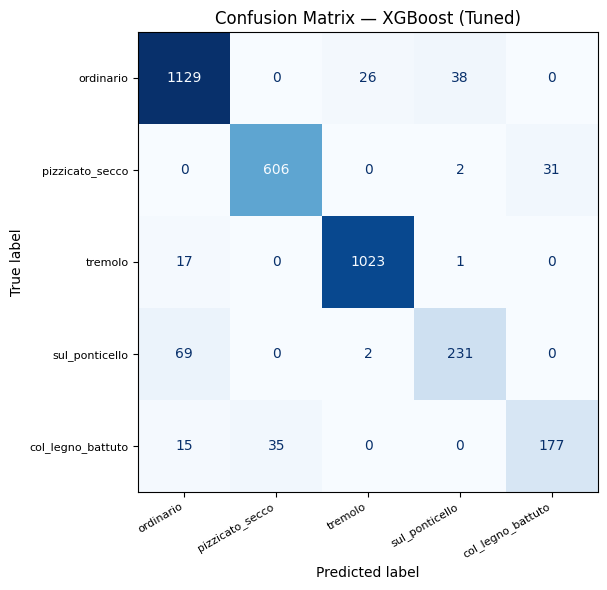

                   precision    recall  f1-score   support

        ordinario       0.92      0.95      0.93      1193
  pizzicato_secco       0.95      0.95      0.95       639
          tremolo       0.97      0.98      0.98      1041
   sul_ponticello       0.85      0.76      0.80       302
col_legno_battuto       0.85      0.78      0.81       227

         accuracy                           0.93      3402
        macro avg       0.91      0.88      0.90      3402
     weighted avg       0.93      0.93      0.93      3402

Saved: confusion_matrix.png, classification_report.txt


In [42]:
# Collect predictions with GroupKFold
y_true_all, y_pred_all = [], []

for train_idx, test_idx in gkf.split(X, y, groups=groups):
    model = xgb.XGBClassifier(**gs.best_params_,
                               eval_metric='mlogloss',
                               random_state=42, n_jobs=-1)
    model.fit(X[train_idx], y[train_idx])
    y_true_all.extend(y[test_idx])
    y_pred_all.extend(model.predict(X[test_idx]))

y_true_all = np.array(y_true_all)
y_pred_all = np.array(y_pred_all)

cm = confusion_matrix(y_true_all, y_pred_all)
fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(cm, display_labels=CLASSES)
disp.plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_xticklabels(CLASSES, rotation=30, ha='right', fontsize=8)
ax.set_yticklabels(CLASSES, fontsize=8)
ax.set_title('Confusion Matrix — XGBoost (Tuned)')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

report = classification_report(y_true_all, y_pred_all, target_names=CLASSES)
print(report)
(RESULTS_DIR / 'classification_report.txt').write_text(report)
print('Saved: confusion_matrix.png, classification_report.txt')

## 6. Feature Importance

XGBoost가 분류에 가장 많이 의존한 특징을 확인한다.  
"어떤 특징이 왜 중요한가"를 음향학적으로 설명하는 것이 이 프로젝트의 핵심 서술이다.

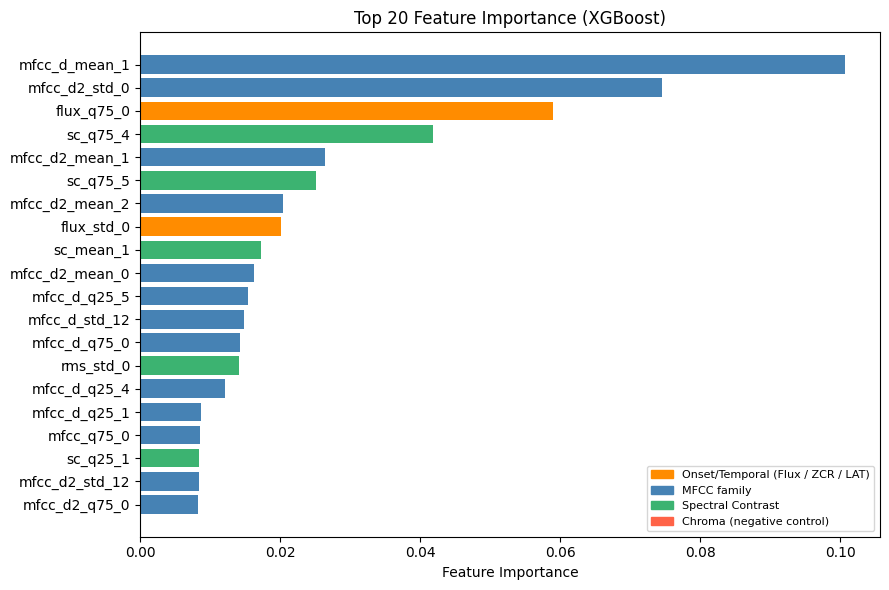

Saved: feature_importance_top20.png, feature_importance.csv


In [43]:
importance = pd.Series(best_xgb.feature_importances_, index=FEATURE_NAMES)
top20 = importance.sort_values(ascending=False).head(20)

fig, ax = plt.subplots(figsize=(9, 6))
colors = []
for name in top20.index:
    if 'chroma' in name:       colors.append('tomato')
    elif 'flux' in name:       colors.append('darkorange')
    elif 'zcr' in name:        colors.append('darkorange')
    elif 'log_attack' in name: colors.append('darkorange')
    elif 'mfcc' in name:       colors.append('steelblue')
    else:                      colors.append('mediumseagreen')

ax.barh(top20.index[::-1], top20.values[::-1], color=colors[::-1])
ax.set_xlabel('Feature Importance')
ax.set_title('Top 20 Feature Importance (XGBoost)')

from matplotlib.patches import Patch
legend = [
    Patch(color='darkorange',    label='Onset/Temporal (Flux / ZCR / LAT)'),
    Patch(color='steelblue',     label='MFCC family'),
    Patch(color='mediumseagreen',label='Spectral Contrast'),
    Patch(color='tomato',        label='Chroma (negative control)'),
]
ax.legend(handles=legend, fontsize=8, loc='lower right')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'feature_importance_top20.png', dpi=150, bbox_inches='tight')
plt.show()

importance.sort_values(ascending=False).to_csv(
    RESULTS_DIR / 'feature_importance.csv', header=['importance']
)
print('Saved: feature_importance_top20.png, feature_importance.csv')

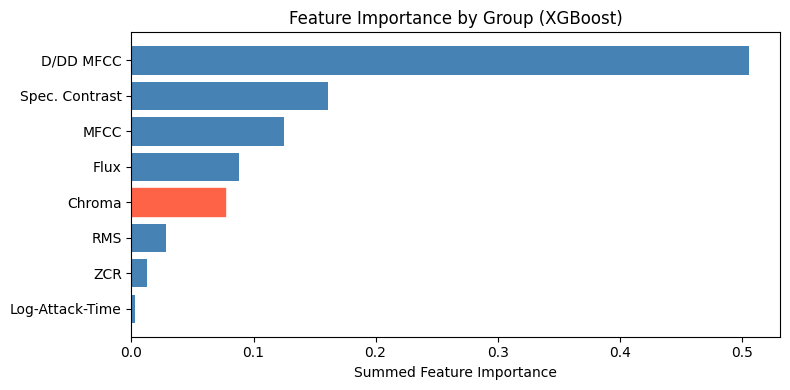

D/DD MFCC          0.5061
Spec. Contrast     0.1608
MFCC               0.1253
Flux               0.0878
Chroma             0.0766
RMS                0.0280
ZCR                0.0127
Log-Attack-Time    0.0029
Saved: feature_importance_by_group.png


In [44]:
groups_map = {
    'MFCC':            importance[[c for c in FEATURE_NAMES if 'mfcc' in c and 'mfcc_d' not in c]].sum(),
    'D/DD MFCC':       importance[[c for c in FEATURE_NAMES if 'mfcc_d' in c]].sum(),
    'Spec. Contrast':  importance[[c for c in FEATURE_NAMES if c.startswith('sc_')]].sum(),
    'Flux':            importance[[c for c in FEATURE_NAMES if 'flux' in c]].sum(),
    'ZCR':             importance[[c for c in FEATURE_NAMES if 'zcr' in c]].sum(),
    'RMS':             importance[[c for c in FEATURE_NAMES if 'rms' in c]].sum(),
    'Chroma':          importance[[c for c in FEATURE_NAMES if 'chroma' in c]].sum(),
    'Log-Attack-Time': importance[['log_attack_time']].sum(),
}
group_imp = pd.Series(groups_map).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(group_imp.index, group_imp.values, color='steelblue')
for bar, name in zip(bars, group_imp.index):
    if name == 'Chroma':
        bar.set_color('tomato')
ax.set_xlabel('Summed Feature Importance')
ax.set_title('Feature Importance by Group (XGBoost)')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'feature_importance_by_group.png', dpi=150, bbox_inches='tight')
plt.show()

print(group_imp.sort_values(ascending=False).round(4).to_string())
print('Saved: feature_importance_by_group.png')

## 7. SHAP 분석

Feature Importance는 "전체적으로" 중요한 특징을 보여준다.  
SHAP은 "이 샘플이 이 클래스로 분류된 이유"를 샘플 단위로 설명한다.

In [45]:
explainer   = shap.TreeExplainer(best_xgb)
shap_values = explainer.shap_values(X)   # shape: (n_samples, n_features, n_classes)
print('SHAP values shape:', np.array(shap_values).shape)

SHAP values shape: (3402, 245, 5)


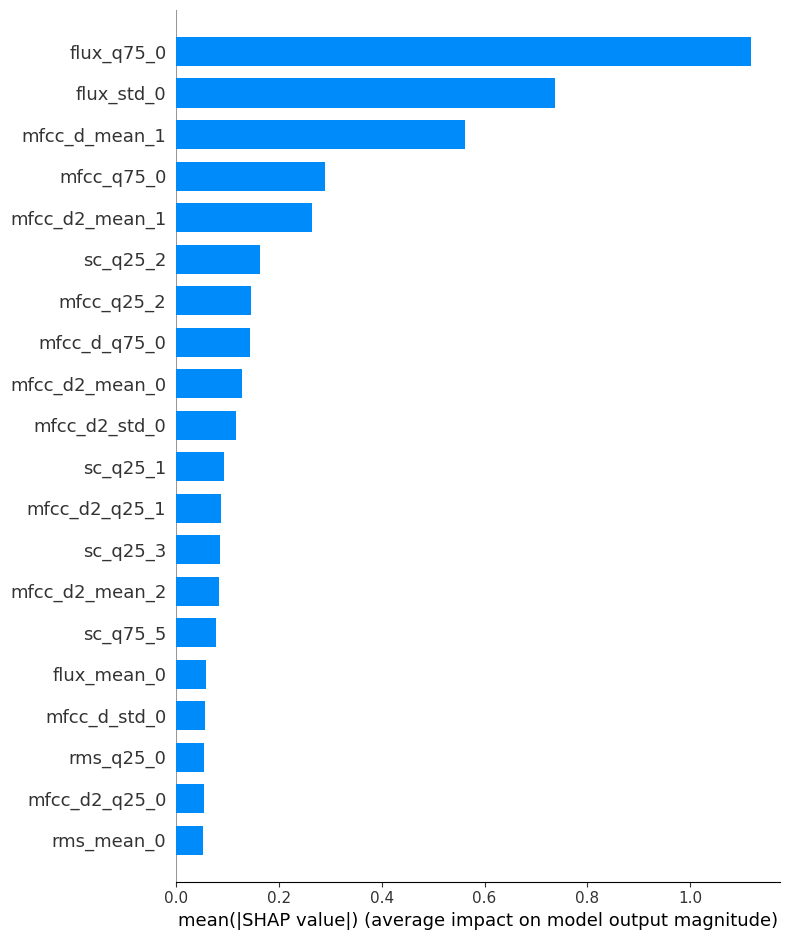

Saved: shap_summary.png


In [46]:
shap_arr = np.array(shap_values)
mean_shap = np.abs(shap_arr).mean(axis=2) if shap_arr.ndim == 3 else shap_arr

shap.summary_plot(
    mean_shap,
    features=X,
    feature_names=FEATURE_NAMES,
    max_display=20,
    plot_type='bar',
    show=False,
)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: shap_summary.png')

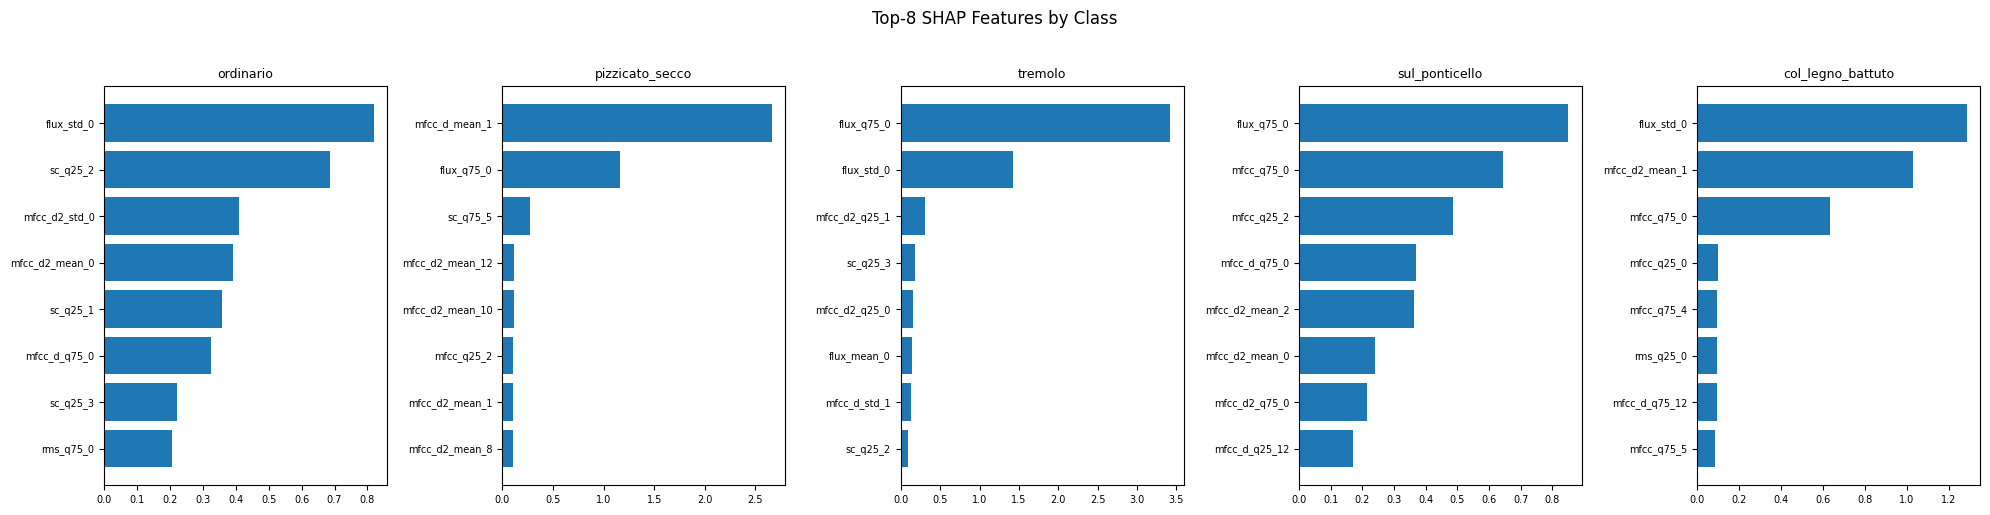

Saved: shap_by_class.png


In [47]:
shap_arr = np.array(shap_values)  # (n_samples, n_features, n_classes)

# per-class slice: shap_arr[:, :, i] → (n_samples, n_features)
fig, axes = plt.subplots(1, len(CLASSES), figsize=(20, 5))
for i, (cls, ax) in enumerate(zip(CLASSES, axes)):
    cls_shap = shap_arr[:, :, i]                      # (1000, 245)
    mean_abs = np.abs(cls_shap).mean(axis=0)           # (245,)
    top_idx  = mean_abs.argsort()[-8:][::-1]
    ax.barh([FEATURE_NAMES[j] for j in top_idx[::-1]], mean_abs[top_idx[::-1]])
    ax.set_title(cls, fontsize=9)
    ax.tick_params(labelsize=7)

plt.suptitle('Top-8 SHAP Features by Class', y=1.02)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'shap_by_class.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: shap_by_class.png')

## 8. Interpretation Summary

### Model Performance

| Model | Test Macro F1 | Std | Note |
|---|---|---|---|
| Random Forest | 0.910 | ±0.041 | Highest mean, but most variance across folds |
| SVM | 0.907 | ±0.005 | Most stable — least sensitive to which instrument is left out |
| XGBoost (tuned) | 0.901 | ±0.000 | GridSearchCV CV score |
| XGBoost (default) | 0.900 | ±0.021 | Tuning gave negligible gain — default params were near-optimal |

All models within ~1% of each other → feature extraction quality, not model choice, is the bottleneck.  
RF's high variance (±0.041) means it's the most sensitive to instrument-specific patterns.

### SHAP Feature Interpretation

| Technique | Top SHAP features | Acoustic explanation |
|---|---|---|
| **pizzicato_secco** | `mfcc_d_mean_1`, `flux_q75_0` | Δ MFCC #1 captures abrupt spectral energy change at the pluck attack; high Flux 75th-percentile reflects the sharp onset |
| **tremolo** | `flux_q75_0`, `flux_std_0` | Rapid repeated bow strokes create periodic onset bursts → both the peak (q75) and variance (std) of Flux are high |
| **col_legno_battuto** | `flux_std_0`, `mfcc_d2_mean_1` | Bow-stick impacts are irregular → Flux variance is highest among all classes; ΔΔ MFCC captures rapid spectral curvature |
| **sul_ponticello** | `mfcc_q75_0`, `flux_q75_0` | Bowing near the bridge enriches upper harmonics → MFCC #0 (overall energy) upper quartile elevated |
| **ordinario** | `sc_q25_1`, `sc_q25_2` | Reference bowing; identified by stable, low-variance harmonic structure → Spectral Contrast lower quartiles are the discriminating signal |

### Unexpected Finding — Chroma

Chroma appeared in 4 of the Top-20 XGBoost features (`chroma_q75_8/5/9/10`), despite being designated as a negative control (pitch-class information should be irrelevant to playing technique).

**Likely cause:** OrchideaSOL records instruments across specific pitch ranges. If certain techniques were recorded more densely in particular pitch regions, the model can exploit that pitch-class co-occurrence as a spurious shortcut. This is a data-distribution artifact, not a generalizable signal.

**Implication for v2 (CNN):** A mel-spectrogram CNN will be even more exposed to this kind of pitch-technique co-occurrence unless pitch augmentation (pitch-shifting) is applied during training.

## 9. Ablation — Chroma Removal

Chroma appeared in Top-20 features despite being a designated negative control.  
Hypothesis: Chroma carries spurious pitch-technique co-occurrence from the dataset, not genuine technique signal.

**Test:** Remove all 48 Chroma dimensions → re-run RF / XGBoost (tuned) / SVM → compare F1.

- If F1 stays the same or rises → Chroma was noise / spurious signal  
- If F1 drops significantly → Chroma carried some genuine signal (unexpected)

Full feature dim: 245  →  No-Chroma dim: 197  (removed 48)


,Model,F1 (full),F1 (no chroma),Delta
0,Random Forest,0.8862,0.8798,-0.0064
1,XGBoost (tuned),0.8914,0.8969,0.0055
2,SVM,0.9159,0.9134,-0.0025


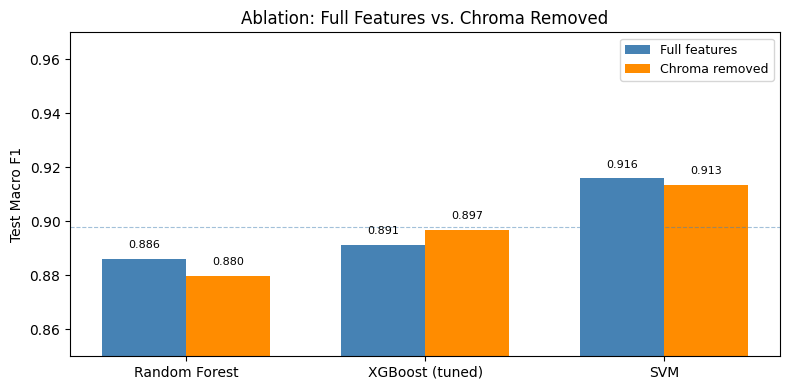

Saved: ablation_chroma.csv, ablation_chroma.png


In [48]:
# Chroma 제거 후 재실험
NO_CHROMA = [c for c in FEATURE_NAMES if 'chroma' not in c]
X_nc = df[NO_CHROMA].values.astype(float)
print(f'Full feature dim: {X.shape[1]}  →  No-Chroma dim: {X_nc.shape[1]}  (removed {X.shape[1] - X_nc.shape[1]})')

def run_cv(model, X_data):
    return cross_validate(model, X_data, y, groups=groups, cv=gkf,
                          scoring='f1_macro', return_train_score=False)

# RF
cv_rf_nc  = run_cv(RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1), X_nc)

# XGBoost (tuned params 재사용)
cv_xgb_nc = run_cv(
    xgb.XGBClassifier(**gs.best_params_, eval_metric='mlogloss', random_state=42, n_jobs=-1),
    X_nc
)

# SVM
cv_svm_nc = run_cv(
    Pipeline([('scaler', StandardScaler()),
              ('svm', SVC(kernel='rbf', C=10, gamma='scale', random_state=42))]),
    X_nc
)

# 비교 테이블
ablation = pd.DataFrame({
    'Model':        ['Random Forest', 'XGBoost (tuned)', 'SVM'],
    'F1 (full)':    [cv_rf['test_score'].mean(),  gs.best_score_,              cv_svm['test_score'].mean()],
    'F1 (no chroma)':[cv_rf_nc['test_score'].mean(), cv_xgb_nc['test_score'].mean(), cv_svm_nc['test_score'].mean()],
}).round(4)
ablation['Delta'] = (ablation['F1 (no chroma)'] - ablation['F1 (full)']).round(4)
display(ablation)
ablation.to_csv(RESULTS_DIR / 'ablation_chroma.csv', index=False)

# 시각화
x = np.arange(len(ablation))
w = 0.35
fig, ax = plt.subplots(figsize=(8, 4))
b1 = ax.bar(x - w/2, ablation['F1 (full)'],     w, label='Full features',    color='steelblue')
b2 = ax.bar(x + w/2, ablation['F1 (no chroma)'], w, label='Chroma removed', color='darkorange')

for bar in list(b1) + list(b2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.004,
            f'{bar.get_height():.3f}', ha='center', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(ablation['Model'])
ax.set_ylabel('Test Macro F1')
ax.set_ylim(0.85, 0.97)
ax.set_title('Ablation: Full Features vs. Chroma Removed')
ax.legend(fontsize=9)
ax.axhline(ablation['F1 (full)'].mean(), color='steelblue', linestyle='--', lw=0.8, alpha=0.5)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'ablation_chroma.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: ablation_chroma.csv, ablation_chroma.png')

## 10. 모델 저장

추론 파이프라인(`src/predict.py`)에서 사용할 모델을 `models/` 디렉토리에 저장한다.

- **svm_v1.joblib** — StandardScaler + SVC를 전체 데이터(3,402개)로 재학습한 파이프라인
- **xgb_v1.joblib** — GridSearchCV 최적 파라미터로 전체 데이터 재학습된 XGBoost (Cell 9에서 이미 완료)

In [49]:
import joblib

MODELS_DIR = Path('../models')
MODELS_DIR.mkdir(exist_ok=True)

# SVM: cross_validate는 fit하지 않으므로 전체 데이터로 재학습 후 저장
best_svm = svm_pipe.fit(X, y)
joblib.dump(best_svm, MODELS_DIR / 'svm_v1.joblib')

# XGBoost: Cell 9에서 이미 전체 데이터로 재학습됨
joblib.dump(best_xgb, MODELS_DIR / 'xgb_v1.joblib')

print('모델 저장 완료:')
print(f'  {(MODELS_DIR / "svm_v1.joblib").resolve()}')
print(f'  {(MODELS_DIR / "xgb_v1.joblib").resolve()}')
print()
print('추론 실행:')
print('  python src/predict.py path/to/audio.wav          # SVM (기본값)')
print('  python src/predict.py path/to/audio.wav --model cnn  # CNN')

모델 저장 완료:
  /Users/juan/Desktop/실습/주법 분류모델/models/svm_v1.joblib
  /Users/juan/Desktop/실습/주법 분류모델/models/xgb_v1.joblib

추론 실행:
  python src/predict.py path/to/audio.wav          # SVM (기본값)
  python src/predict.py path/to/audio.wav --model cnn  # CNN
